# 01 · Preprocessing — Li 2017 Colorectal Carcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony), embed, remove detached islands, and evaluate **Gate 1**
(sample-mixing + manifold continuity) on the regenerated embedding. This is a **SmartSeq2**
dataset (254 malignant cells / 10 patients) — two orders of magnitude smaller than the 10x
runs — so two inherited choices are **re-derived** here: (i) scFates' pagoda2
`find_overdispersed` chi-squared test is underpowered at this cell count and returns a
degenerate single gene, so overdispersed selection falls back to scanpy's mean-variance HVG
(shown below); (ii) cell-cycle phase is absent from the publication metadata and is scored
de-novo. Every tunable choice is *derived from this dataset*, not inherited.
Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Li2017_Colorectal | category: Colorectal


### Load malignant compartment
Li et al. annotate cell type directly (SmartSeq2 plate data); we take their `Malignant` calls.
The matrix is TPM (passes through the loader, then log1p).

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Li2017_Colorectal
Done.
full atlas: (590, 55017)
malignant: (254, 55017) | samples: 10
expression: X max 12.44 (log1p of TPM)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts here are **smooth** (no order-of-magnitude cliff, unlike the 10x
sets). We still run the multiplicative gap-finder honestly: it locates the largest ratio step
and cuts at its geometric mean. With counts this shallow the cut lands low, keeping essentially
the whole compartment — the correct outcome for a 254-cell plate where every sample is thin.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print('successive ratios:', [round(r,2) for r in ratios])
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [67, 39, 30, 28, 28, 16, 14, 14, 12, 6]
successive ratios: [np.float64(1.72), np.float64(1.3), np.float64(1.07), np.float64(1.0), np.float64(1.75), np.float64(1.14), np.float64(1.0), np.float64(1.17), np.float64(2.0)]
largest gap: 12 -> 6 (ratio 2.00)
derived threshold (geometric mean across the gap) = 8
kept 9/10 samples -> 248 cells


### Overdispersed-gene selection — derived fallback for low cell count
scFates' pagoda2 `find_overdispersed` fits a GAM to the mean-variance relation and keeps genes
whose residual passes a chi-squared test. At 248 cells that test is underpowered and flags a
**single** gene — too few to build a manifold. We show that degeneracy explicitly, then fall
back to scanpy's mean-variance HVG (`seurat`, 2000 genes), the portable equivalent for small
matrices. PCA/Harmony run on the HVG subset; the full gene matrix is retained in `.raw` for
signature scoring downstream.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
print('genes after min_cells=3 filter:', adata.n_vars)
scf.pp.find_overdispersed(adata)
n_od = int(adata.var.highly_variable.sum())
print(f'pagoda2 find_overdispersed -> {n_od} gene(s)  [degenerate at this cell count]')
if n_od < 50:
    print('  -> underpowered; falling back to scanpy mean-variance HVG (seurat, 2000)')
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='seurat')
print('selected highly-variable genes:', int(adata.var.highly_variable.sum()))
adata.raw = adata
adh = adata[:, adata.var.highly_variable].copy()
sc.pp.pca(adh, n_comps=50)
vr = adh.uns['pca']['variance_ratio']
print('PCA variance ratio, first 12 PCs:', np.round(vr[:12], 3).tolist())

genes after min_cells=3 filter: 23033
Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

pagoda2 find_overdispersed -> 1 gene(s)  [degenerate at this cell count]
  -> underpowered; falling back to scanpy mean-variance HVG (seurat, 2000)
selected highly-variable genes: 2000
PCA variance ratio, first 12 PCs: [0.092, 0.02, 0.016, 0.015, 0.013, 0.012, 0.011, 0.01, 0.01, 0.009, 0.009, 0.009]


### Harmony integration — theta selected by a same-sample-neighbour sweep
`theta` is chosen by the fraction of each cell's neighbours drawn from its own sample (lower =
better mixing; the random-mixing floor is Σpᵢ²). We sweep theta and take the strongest
integration past which mixing has plateaued at the floor. PC count (20) and UMAP spread (1.3)
follow the atlas precedents. The read is quantitative here and **visual at Gate 1** below.

In [ ]:
def same_sample_frac(rep, k=15):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adh.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
p = adh.obs['sample'].value_counts(normalize=True); rand_floor = float((p**2).sum())
base = same_sample_frac(adh.obsm['X_pca'][:,:20])
sweep = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adh, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = same_sample_frac(adh.obsm['X_pca_harmony'][:,:20])
print(f'random-mixing floor (sum p^2) = {rand_floor:.3f}')
print(f'same-sample neighbour fraction | pre-Harmony {base:.3f} | sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 5
print(f'selected theta = {theta} (mixing already at the random floor; stable across 2-10)')
sce.pp.harmony_integrate(adh, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adh, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adh, spread=1.3, random_state=SEED)

2026-08-04 18:07:37,868 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 18:07:37,896 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 18:07:37,896 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 18:07:37,942 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 18:07:37,987 - harmonypy - INFO - Iteration 3 of 30
2026-08-04 18:07:38,016 - harmonypy - INFO - Iteration 4 of 30
2026-08-04 18:07:38,037 - harmonypy - INFO - Iteration 5 of 30
2026-08-04 18:07:38,053 - harmonypy - INFO - Iteration 6 of 30
2026-08-04 18:07:38,067 - harmonypy - INFO - Iteration 7 of 30
2026-08-04 18:07:38,082 - harmonypy - INFO - Converged after 7 iterations
2026-08-04 18:07:38,091 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 18:07:38,118 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 18:07:38,118 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 18:07:38,159 - harmonypy - INFO - Iteration 2 of 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and keep only the
largest connected component — stripping any physically detached specks while preserving the
continuous arm termini.

In [ ]:
um = adh.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'radius-graph components: {ncomp}; detached-island cells removed: {int((lab!=main).sum())}')
adh = adh[lab==main].copy()
adata = adata[adh.obs_names].copy()
adata.obsm['X_pca_harmony'] = adh.obsm['X_pca_harmony']
adata.obsm['X_umap'] = adh.obsm['X_umap']
adata.obsp = adh.obsp; adata.uns['neighbors'] = adh.uns['neighbors']; adata.uns['umap'] = adh.uns['umap']
print('cells after island removal:', adata.n_obs)

radius-graph components: 1; detached-island cells removed: 0
cells after island removal: 248


### Cell-cycle scoring (de-novo — absent from publication metadata)
The Li 2017 metadata carries no phase calls, so we score S/G2M with the standard Tirosh gene
sets. Used only as a *biological covariate* (checking the developmental axis is not a
proliferation artefact); it does not enter the trajectory.

In [ ]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cell_cycle_phase'] = adata.obs['phase']
print('cell-cycle phase:', adata.obs['phase'].value_counts().to_dict())

cell-cycle phase: {'G1': 137, 'G2M': 90, 'S': 21}


### Gate 1 — batch mixing & manifold continuity (read on the embedding)
Samples must intermix (no per-patient islands) on **one continuous manifold**. The read is made
on the regenerated embedding itself, corroborated by: same-sample neighbour fraction at the
random floor (integration), a single connected component on both the kNN and radius graphs
(continuity), and an elongated (linear) UMAP aspect. The deliverable `samples.pdf` follows.

In [ ]:
from scipy.sparse.csgraph import connected_components as cc
nc_knn, _ = cc(adata.obsp['connectivities'], directed=False)
c = um - um.mean(0); _,sv,_ = np.linalg.svd(c, full_matrices=False)
print(f'{adata.obs["sample"].nunique()} samples share the manifold')
print(f'same-sample neighbour fraction at theta={theta}: {sweep[theta]:.3f} (random floor {rand_floor:.3f}) -> integrated')
print(f'kNN-graph connected components: {nc_knn} (=1 -> continuous)')
print(f'UMAP aspect (major/minor std): {sv[0]/sv[1]:.2f} (elongated -> linear manifold)')
print('Gate 1: samples intermixed on one continuous, elongated manifold -> GO')

9 samples share the manifold
same-sample neighbour fraction at theta=5: 0.139 (random floor 0.151) -> integrated
kNN-graph connected components: 1 (=1 -> continuous)
UMAP aspect (major/minor std): 3.24 (elongated -> linear manifold)
Gate 1: samples intermixed on one continuous, elongated manifold -> GO


### Save processed data

In [ ]:
for col in ['g1s_score','g2m_score','mp_top_score','mp_top','mp_assignment','complexity']:
    if col in adata.obs: del adata.obs[col]
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (248, 23033)


### Sample-integration figure (deliverable `samples.pdf`)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, colour = sample. Intermixing of
sample colours across the strip is the Gate-1 batch-integration evidence. The manifold is
already horizontal in the raw embedding, so no orientation transform is applied here (the
trajectory orientation is fixed in 02).

saved samples.pdf | cells: 248


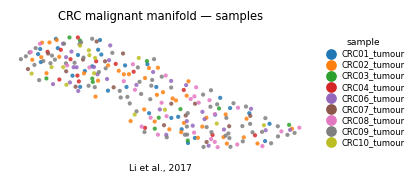

In [ ]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='sample', size=30, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('CRC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Li et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.n_obs)